# 04 · Artificial Neural Network (ANN)

The original project ([sinanw/ann-bank-customer-retention](https://github.com/sinanw/ann-bank-customer-retention)) focused on a small feed-forward neural network built in TensorFlow/Keras (and separately in PyTorch). This notebook:

1. **Rebuilds the original TensorFlow architecture** (credited to the original author) on our shared train/test split, so it can be compared fairly with the other models.
2. **Trains an improved version** with a validation set and early stopping, two standard practices the original didn't use.
3. **Adds both networks to the model comparison** from notebook 03 and discusses whether a neural network is the right tool for this business problem.

Only the TensorFlow version is carried forward. The PyTorch notebook in the original repository used the same architecture, so it would add a second deep-learning dependency without adding new insight.

In [1]:
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's low-level C++ log messages

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

from src.churn_utils import (
    COLOR_CHURN,
    COLOR_MUTED,
    COLOR_PRIMARY,
    METRICS_PATH,
    RANDOM_STATE,
    TEST_PREDICTIONS_PATH,
    build_preprocessor,
    classification_metrics,
    load_train_test,
    save_figure,
    set_plot_style,
)

set_plot_style()
keras.utils.set_random_seed(RANDOM_STATE)       # reproducible weight initialisation and shuffling
tf.config.experimental.enable_op_determinism()  # reproducible results on CPU
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Prepare the inputs

Neural networks need numeric, similarly-scaled inputs, so we use the same shared preprocessor as every other model: one-hot encoding plus standardisation, **fit on the training set only**.

In [2]:
X_train, X_test, y_train, y_test, test_customer_ids = load_train_test()

preprocessor = build_preprocessor().fit(X_train)
X_train_nn = preprocessor.transform(X_train).astype("float32")
X_test_nn = preprocessor.transform(X_test).astype("float32")
y_train_nn = y_train.to_numpy().astype("float32")

n_features = X_train_nn.shape[1]
print(f"{n_features} input features, {len(X_train_nn):,} training rows, {len(X_test_nn):,} test rows")

12 input features, 8,000 training rows, 2,000 test rows


## 2. Model A: the original architecture

*Architecture from the original project:*

| Layer | Units | Activation |
|---|---|---|
| Hidden 1 | 6 | ReLU |
| Hidden 2 | 6 | ReLU |
| Output | 1 | Sigmoid (outputs a churn probability between 0 and 1) |

Training settings are also kept from the original: Adam optimiser, binary cross-entropy loss, batch size 32, **100 epochs on the full training set** with no validation monitoring.

In [3]:
def build_original_ann(n_inputs):
    """6-6-1 network from the original project."""
    model = keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        layers.Dense(6, activation="relu"),
        layers.Dense(6, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model


keras.utils.set_random_seed(RANDOM_STATE)
original_ann = build_original_ann(n_features)
original_ann.summary()

original_history = original_ann.fit(X_train_nn, y_train_nn, batch_size=32, epochs=100, verbose=0)
print(f"Final training loss: {original_history.history['loss'][-1]:.4f}, "
      f"training AUC: {original_history.history['auc'][-1]:.3f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 127 (508.00 B)

 Trainable params: 127 (508.00 B)

 Non-trainable params: 0 (0.00 B)

Final training loss: 0.3378, training AUC: 0.863


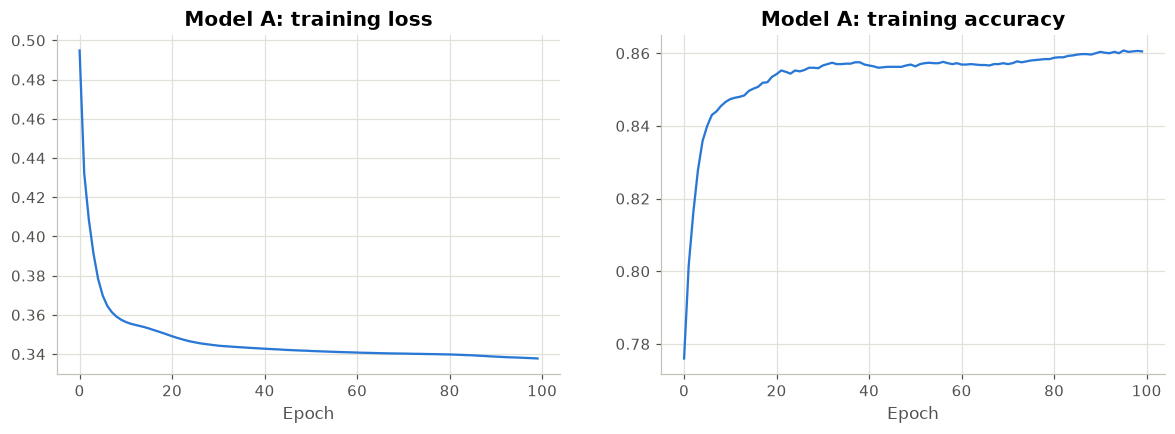

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(original_history.history["loss"], color=COLOR_PRIMARY)
axes[0].set_title("Model A: training loss")
axes[1].plot(original_history.history["accuracy"], color=COLOR_PRIMARY)
axes[1].set_title("Model A: training accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True)
plt.show()

The training loss falls quickly in the first 10–20 epochs and then flattens. Training accuracy levels off around 86%. Because the original setup has no validation set, these curves only tell us the model has *converged on the training data*. They can't tell us whether it generalises. The test results in Section 4 answer that.

## 3. Model B: improved training procedure

The original setup has two weaknesses:
1. **No validation data.** Without it you can't tell whether 100 epochs is too few or too many (underfitting vs overfitting).
2. **A very small network** (6 neurons per layer) may not have the capacity to learn interactions such as *age × activity*.

Model B makes three changes:
* **15% of the training data is held out as a validation set** (stratified). The test set stays untouched.
* **Slightly larger layers (32 → 16) with dropout (20%)**. Dropout randomly switches off neurons during training, which discourages memorising the training data.
* **Early stopping** monitors validation ROC-AUC, stops when it hasn't improved for 20 epochs, and restores the best weights.

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_nn, y_train_nn, test_size=0.15, stratify=y_train_nn, random_state=RANDOM_STATE
)

def build_improved_ann(n_inputs):
    model = keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


keras.utils.set_random_seed(RANDOM_STATE)
improved_ann = build_improved_ann(n_features)
early_stopping = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=20,
                                               restore_best_weights=True)
improved_history = improved_ann.fit(
    X_fit, y_fit, validation_data=(X_val, y_val), batch_size=32, epochs=300,
    callbacks=[early_stopping], verbose=0,
)
best_epoch = int(np.argmax(improved_history.history["val_auc"])) + 1
print(f"Stopped after {len(improved_history.history['loss'])} epochs; best validation AUC "
      f"{max(improved_history.history['val_auc']):.3f} at epoch {best_epoch}")

Stopped after 60 epochs; best validation AUC 0.861 at epoch 40


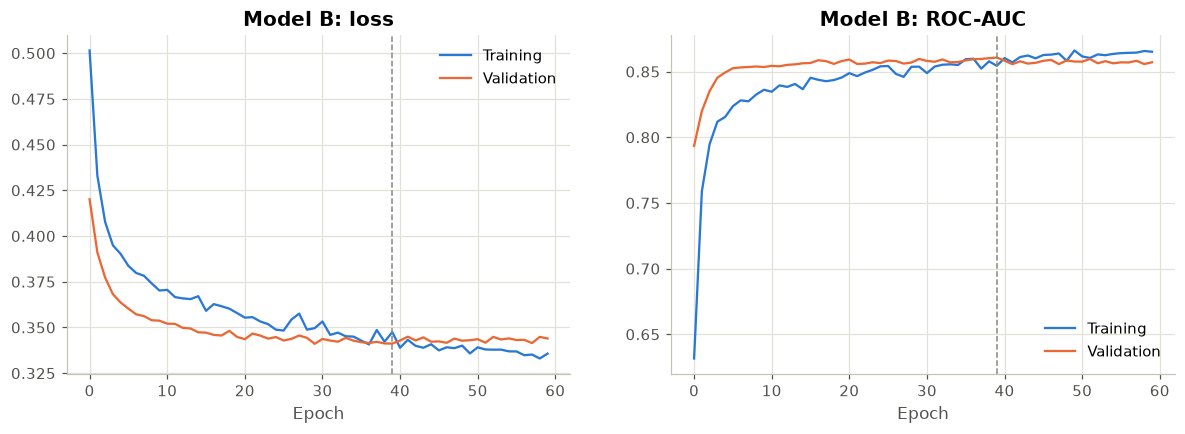

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(improved_history.history["loss"], color=COLOR_PRIMARY, label="Training")
axes[0].plot(improved_history.history["val_loss"], color=COLOR_CHURN, label="Validation")
axes[0].set_title("Model B: loss")
axes[1].plot(improved_history.history["auc"], color=COLOR_PRIMARY, label="Training")
axes[1].plot(improved_history.history["val_auc"], color=COLOR_CHURN, label="Validation")
axes[1].set_title("Model B: ROC-AUC")
for ax in axes:
    ax.axvline(best_epoch - 1, color=COLOR_MUTED, linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)
save_figure(fig, "04_ann_training_curves")
plt.show()

* Validation AUC peaked at about **0.861 at epoch 40**, and training stopped 20 epochs later. Early stopping restored the epoch-40 weights.
* Training and validation loss stay close together, so there is **no strong overfitting**. With 12 inputs and 8,000 rows, even the larger network has limited room to memorise.

## 4. Evaluate both networks on the test set

In [7]:
ann_probabilities = {
    "ANN (original 6-6-1)": original_ann.predict(X_test_nn, verbose=0).ravel(),
    "ANN (improved, early stopping)": improved_ann.predict(X_test_nn, verbose=0).ravel(),
}
ann_results = pd.DataFrame({name: classification_metrics(y_test, p) for name, p in ann_probabilities.items()}).T
ann_results.style.format("{:.3f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
ANN (original 6-6-1),0.863,0.775,0.457,0.575,0.864
"ANN (improved, early stopping)",0.864,0.808,0.435,0.565,0.864


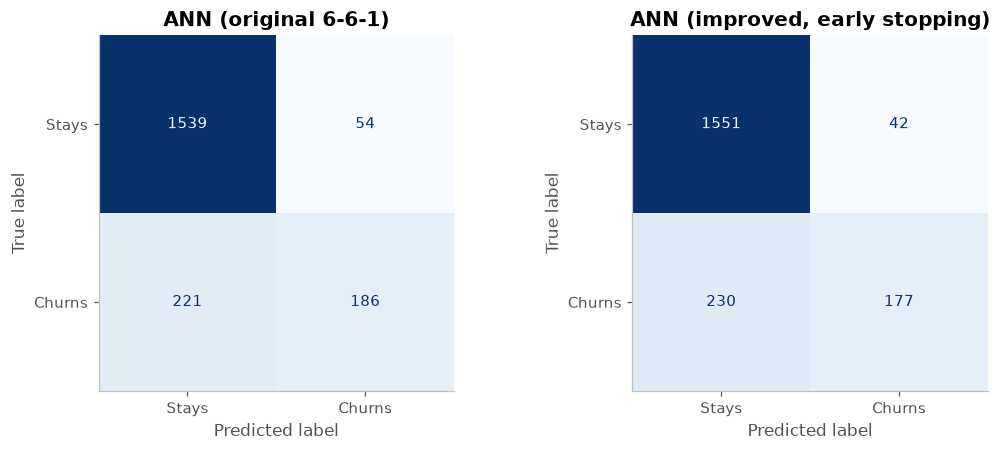

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, probabilities) in zip(axes, ann_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (probabilities >= 0.5).astype(int),
                                            display_labels=["Stays", "Churns"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

## 5. Final comparison: all models on the same test set

All rows below are evaluated on the **same 2,000 test customers** at the **same 0.5 threshold**.

In [9]:
classical_results = pd.read_csv(METRICS_PATH, index_col="Model")
classical_results = classical_results.drop(index=[m for m in ann_results.index if m in classical_results.index])
all_results = pd.concat([classical_results, ann_results.round(4)]).rename_axis("Model")
all_results = all_results.sort_values("ROC-AUC", ascending=False)
all_results.to_csv(METRICS_PATH)

# Store ANN test probabilities next to the other models' predictions
predictions = pd.read_csv(TEST_PREDICTIONS_PATH)
for name, probabilities in ann_probabilities.items():
    predictions[name] = probabilities.round(5)
predictions.to_csv(TEST_PREDICTIONS_PATH, index=False)

all_results.style.format("{:.3f}").highlight_max(axis=0, subset=["Precision", "Recall", "F1", "ROC-AUC"],
                                                 props="font-weight:bold; background-color:#e8f0fb")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost,0.869,0.787,0.489,0.603,0.871
ANN (original 6-6-1),0.863,0.775,0.457,0.575,0.864
"ANN (improved, early stopping)",0.864,0.808,0.435,0.566,0.864
Random Forest,0.867,0.834,0.432,0.570,0.862
Decision Tree,0.861,0.778,0.440,0.562,0.846
Logistic Regression,0.807,0.617,0.142,0.232,0.776


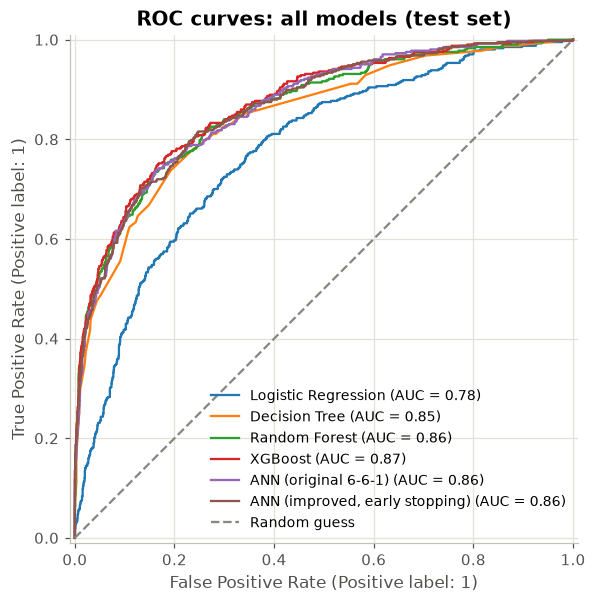

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
model_columns = [c for c in predictions.columns if c not in ("CustomerId", "Exited")]
for name in model_columns:
    RocCurveDisplay.from_predictions(predictions["Exited"], predictions[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color=COLOR_MUTED, label="Random guess")
ax.set_title("ROC curves: all models (test set)")
ax.legend(loc="lower right", fontsize=9)
ax.grid(True)
save_figure(fig, "04_roc_all_models")
plt.show()

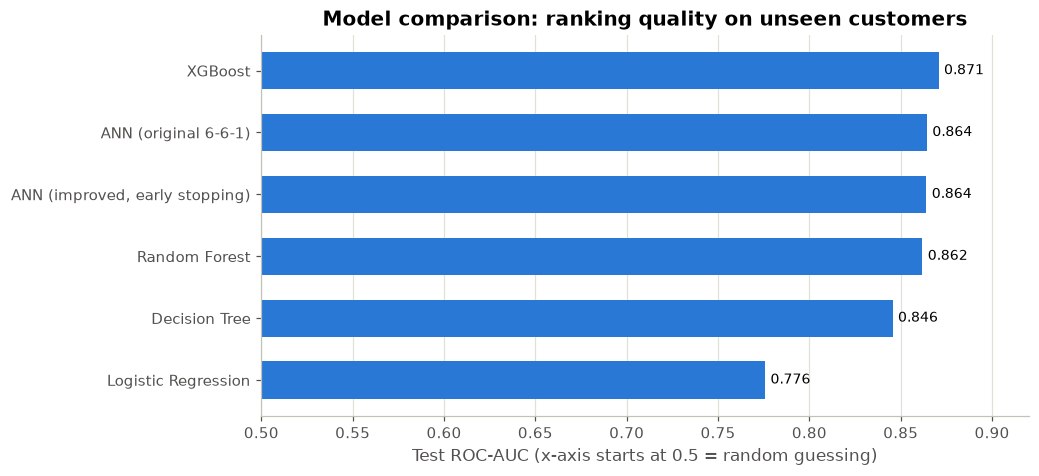

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = all_results.sort_values("ROC-AUC")
ax.barh(plot_data.index, plot_data["ROC-AUC"], color=COLOR_PRIMARY, height=0.6)
for y, v in enumerate(plot_data["ROC-AUC"]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.5, 0.92)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Test ROC-AUC (x-axis starts at 0.5 = random guessing)")
ax.set_title("Model comparison: ranking quality on unseen customers")
save_figure(fig, "04_model_comparison_auc")
plt.show()

### What the comparison shows
* **XGBoost remains the best model** on every churn-class metric at the 0.5 threshold (ROC-AUC 0.871, recall 0.489, F1 0.603).
* **Both neural networks land at ROC-AUC 0.864**, slightly ahead of Random Forest (0.862) and well ahead of logistic regression (0.776). The ANN is competitive, but it doesn't beat gradient boosting.
* **The "improved" ANN didn't improve the test results.** Making the network bigger and adding early stopping changed almost nothing (0.864 vs 0.864). This suggests the limit is the **information in the 10 available features**, not the capacity of the model. Better data (e.g. transaction history, complaints, digital engagement) would likely help more than a more complex model.
* The differences between the top four models (0.862–0.871) are small, about the size of the fold-to-fold variation seen in cross-validation (±0.01). We shouldn't over-interpret the exact ranking.

### Why XGBoost, not the ANN, is used in the dashboard and business analysis
| Consideration | XGBoost | ANN |
|---|---|---|
| Test ROC-AUC | **0.871** | 0.864 |
| Explainability for business users | Feature importance and SHAP values are fast and exact for trees | Harder to explain; needs approximate methods |
| Deployment | Small model file, no deep-learning framework needed | Requires TensorFlow at prediction time |
| Sensitivity to preprocessing | Low (trees don't need scaling) | Requires correctly scaled inputs |

For a bank, being able to **explain why a customer was flagged** (to relationship managers, and potentially to regulators) matters as much as a small gain in accuracy. On this dataset the more explainable model is also the more accurate one, so the choice is easy.

> **Reproducibility note:** neural-network results can vary slightly between machines and TensorFlow versions, even with fixed random seeds. Expect ROC-AUC within about ±0.005 of the values above if you re-run this notebook.